# 📊 01. Comprehensive EDA & Preprocessing Pipeline Verification for Sensor Modality

**Project:** Durian Ripeness Classification via Cross-Modal Knowledge Distillation (CMKD)  
**Responsible:** Member 3 (Sensor / Tabular / Spectral / Thermal Modalities)  
**Reference Documents:** `specification/Đặc tả đề tài.pdf` (Sections 1.3.1 & 1.3.2) and `README.md`

---

### 🎯 Core Objectives:
1. **Environment & Google Drive Automation:** Automatically clone source code from GitHub (`cocobaut` branch), mount Google Drive, and locate `data/split_data` consistently across Colab and Local environments.
2. **Physicochemical Tabular EDA:** Investigate 189 fruits (`durian_characteristics_cleaned.csv`), analyze missingness mechanisms (MNAR in Overripe), and perform biochemical correlation analysis (Pearson, Spearman, Kruskal-Wallis, Mann-Whitney U).
3. **Thermal Matrix Processing:** Otsu background segmentation combined with fruit core analysis, extracting temperature difference $\Delta T = T_{\text{fruit}} - T_{\text{background}}$ to eliminate room temperature confounding.
4. **Multispectral Mosaic Processing:** Decompose 2D mosaic $(512, 1024)$ into 3D 8-band tensor $(256, 256, 8)$ and extract reflectance spectral signatures.
5. **Outlier & Robust Scaler Experiments:** Benchmark pure `StandardScaler`, `StandardScaler + Winsorization` (quantile clipping), and `RobustScaler` (Median/IQR).
6. **Multi-Sensor Integration:** Fuse multi-angle features and evaluate classification performance when combining Tabular + Thermal + Multispectral.
7. **PyTorch Pipeline Verification:** Package `SensorPreprocessor`, `SensorDataset`, and `SensorBackbone` (MLP) ready for integration into the multimodal Teacher model.
8. **Independent Test Set Evaluation:** Establish the official Unimodal Sensor Baseline benchmark and elucidate the role of **Learning Under Privileged Information (LUPI)**.

### 1. Environment Setup, Git Clone (cocobaut branch), Mount Drive & Library Imports

In [1]:
# 1.1. Automatic Git repository cloning (cocobaut branch), Drive mounting, and library imports
import os
import re
import sys
import shutil
import warnings
import subprocess
from pathlib import Path

# Automatically reload changes from preprocess_sensor.py module
try:
    import IPython
    ip = IPython.get_ipython()
    if ip is not None:
        ip.run_line_magic('load_ext', 'autoreload')
        ip.run_line_magic('autoreload', '2')
except Exception:
    pass

# ------------------------------------------------------------------------------
# 1. AUTOMATICALLY CLONE GITHUB REPO (cocobaut BRANCH) WHEN RUNNING ON GOOGLE COLAB
# ------------------------------------------------------------------------------
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if IN_COLAB:
    REPO_URL = "https://github.com/Cocobaut/durian-ripeness-classification.git"
    REPO_DIR = "/content/durian-ripeness-classification"
    WORKSPACE_DIR = os.path.join(REPO_DIR, "workspaces", "member3_sensor", "01_eda_and_preprocess_sensor")

    if not os.path.exists(REPO_DIR):
        print(f"[*] Automatically cloning repository from GitHub (cocobaut branch): {REPO_URL} ...")
        subprocess.run(["git", "clone", "-b", "cocobaut", REPO_URL, REPO_DIR], check=True)
        print("✅ Successfully cloned repository to /content/durian-ripeness-classification (cocobaut branch)")
    else:
        print("[*] Repository already exists, updating latest code from cocobaut branch...")
        try:
            subprocess.run(["git", "-C", REPO_DIR, "checkout", "cocobaut"], check=False)
            subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin", "cocobaut"], check=False)
            subprocess.run(["git", "-C", REPO_DIR, "reset", "--hard", "origin/cocobaut"], check=False)
        except Exception:
            pass

    # Add paths to sys.path
    for p in [WORKSPACE_DIR, REPO_DIR]:
        if os.path.exists(p) and p not in sys.path:
            sys.path.insert(0, p)

    # Switch working directory to workspace for relative paths to work correctly
    if os.path.exists(WORKSPACE_DIR):
        os.chdir(WORKSPACE_DIR)
        print(f"✅ Current working directory: {os.getcwd()}")

# Install required libraries if missing in Colab (mapping pip package to import name)
REQUIRED_PACKAGES = {
    "tifffile": "tifffile",
    "scikit-image": "skimage",
    "joblib": "joblib",
}
for pip_name, mod_name in REQUIRED_PACKAGES.items():
    try:
        __import__(mod_name)
    except ImportError:
        print(f"Installing missing dependency: {pip_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

# ------------------------------------------------------------------------------
# 2. CONNECT TO GOOGLE DRIVE & RESOLVE DATA PATHS
# ------------------------------------------------------------------------------
if IN_COLAB:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    print("✅ Google Drive mounted successfully at /content/drive")

    candidate_split_dirs = [
        Path("/content/drive/MyDrive/durian-ripeness-cmkd/data/split_data"),
        Path("/content/drive/MyDrive/durian-ripeness-classification/data/split_data"),
        Path("/content/durian-ripeness-classification/data/split_data"),
        Path("../../../data/split_data"),
    ]
    SPLIT_DIR = None
    for cand in candidate_split_dirs:
        if cand.exists() and (cand / "sample_split_mapping.csv").exists():
            SPLIT_DIR = cand
            break
    if SPLIT_DIR is None:
        SPLIT_DIR = Path("../../../data/split_data")
else:
    def find_split_dir(start_path: Path) -> Path:
        for parent in [start_path] + list(start_path.parents):
            candidate = parent / "data" / "split_data"
            if candidate.exists():
                return candidate
        return Path("../../../data/split_data")
    SPLIT_DIR = find_split_dir(Path.cwd())

SPLITS = ["train", "val", "test"]
paths = {s: SPLIT_DIR / s / "durian_characteristics_cleaned.csv" for s in SPLITS}

print(f"📂 Current working directory : {Path.cwd()}")
print(f"📦 Data directory split_data : {SPLIT_DIR.resolve()}")
status = {k: v.exists() for k, v in paths.items()}
print(f"✅ CSV file status           : {status}")

assert all(status.values()), "❌ ERROR: Missing one or more CSV files (train/val/test). Please check data/split_data!"

# Ensure preprocess_sensor.py module can be imported across environments
def ensure_preprocess_sensor():
    candidates = [
        os.path.abspath("."),
        os.path.abspath(".."),
        os.path.abspath("../../.."),
        "/content/durian-ripeness-classification/workspaces/member3_sensor/01_eda_and_preprocess_sensor",
        "/content/drive/MyDrive/durian-ripeness-cmkd/workspaces/member3_sensor/01_eda_and_preprocess_sensor",
    ]
    for c in candidates:
        if os.path.exists(os.path.join(c, "preprocess_sensor.py")):
            if c not in sys.path:
                sys.path.insert(0, c)
            print(f"✅ Found module 'preprocess_sensor.py' at: {c}")
            return

ensure_preprocess_sensor()

# Clear module cache if an older version was loaded in current session
for mod in list(sys.modules.keys()):
    if "preprocess_sensor" in mod:
        del sys.modules[mod]

# Import components from preprocess_sensor.py
from preprocess_sensor import (
    CLASS_ORDER, DEFAULT_FEATURE_COLS, THERMAL_FEATURE_COLS,
    MULTISPECTRAL_FEATURE_COLS, INTEGRATED_SENSOR_COLS,
    SensorPreprocessor, SensorDataset, SensorBackbone,
    make_fruit_id, extract_thermal_features, extract_multispectral_features,
    extract_fruit_thermal_vector, extract_fruit_multispectral_vector,
    build_integrated_sensor_dataframe, load_thermal_matrix, safe_read_tif,
    unpack_multispectral_grid
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy.stats import kruskal, mannwhitneyu
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

Mounted at /content/drive
✅ Google Drive đã được kết nối tại /content/drive
📂 Thư mục làm việc hiện tại : /content/durian-ripeness-classification/workspaces/member3_sensor/01_eda_and_preprocess_sensor
📦 Thư mục dữ liệu split_data: /content/drive/MyDrive/durian-ripeness-cmkd/data/split_data
✅ Trạng thái file CSV       : {'train': True, 'val': True, 'test': True}
✅ Đã tìm thấy module 'preprocess_sensor.py' tại: /content/durian-ripeness-classification/workspaces/member3_sensor/01_eda_and_preprocess_sensor


In [2]:
# Check and compare with original split mapping (sample_split_mapping.csv)
MAPPING_PATH = Path(SPLIT_DIR) / "sample_split_mapping.csv"

if MAPPING_PATH.exists():
    mp = pd.read_csv(MAPPING_PATH)
    print("Columns in sample_split_mapping.csv:", mp.columns.tolist())
    display(mp.head(5))
    display(mp.describe(include="all").T)
    
    # Split distribution in original mapping file
    if "split" in mp.columns:
        print("\nSample distribution across splits in original mapping file:")
        print(mp["split"].value_counts().to_dict())
else:
    print(f"⚠️ File not found at: {MAPPING_PATH}")

Các cột trong sample_split_mapping.csv: ['sample_id', 'Replicate', 'Code', 'Ripeness', 'Maturity_Stage', 'Split']


,sample_id,Replicate,Code,Ripeness,Maturity_Stage,Split
0,1,R1,IM_CA_UN_1,Unripe,Immature,test
1,2,R2,IM_CA_UN_2,Unripe,Immature,train
2,3,R3,IM_CA_UN_3,Unripe,Immature,val
3,4,R4,IM_CA_UN_4,Unripe,Immature,train
4,5,R5,IM_CA_UN_5,Unripe,Immature,val


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sample_id,189.0,NaN,NaN,NaN,95.0,54.703748,1.0,48.0,95.0,142.0,189.0
Replicate,189,189,R1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Code,189,189,IM_CA_UN_1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ripeness,189,3,Unripe,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Maturity_Stage,189,3,Immature,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Split,189,3,train,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2. EDA: Tabular Structure Inspection & Missing Values Audit

In [3]:
# Tabular EDA Guidelines:
# 1. Read CSV files with pandas: df = pd.read_csv(CSV_PATH)
# 2. Print row count (fruit count) and column count
# 3. Audit missing value (NaN) ratios per feature column: df.isnull().sum()
# 4. Use df.describe() to inspect distributions (mean, min, max, standard deviation)

from preprocess_sensor import make_fruit_id

# Step 1: Read CSV files for all 3 splits
train_df = pd.read_csv(paths["train"])
val_df   = pd.read_csv(paths["val"])
test_df  = pd.read_csv(paths["test"])

# Step 2: Check shapes, column schemas & verify zero leakage
print(f"Shapes train / val / test: {train_df.shape} / {val_df.shape} / {test_df.shape}")
assert (len(train_df), len(val_df), len(test_df)) == (132, 28, 29), "Sample counts do not match standard 132/28/29!"
assert list(train_df.columns) == list(val_df.columns) == list(test_df.columns), "Column schemas are inconsistent across splits!"

# Verify fruit_id uniqueness internally and disjointness across splits
ids_tr, ids_va, ids_te = map(set, (make_fruit_id(train_df), make_fruit_id(val_df), make_fruit_id(test_df)))
assert len(ids_tr) == 132 and len(ids_va) == 28 and len(ids_te) == 29, "Duplicate fruit_id within a split!"
assert ids_tr.isdisjoint(ids_va) and ids_tr.isdisjoint(ids_te) and ids_va.isdisjoint(ids_te), "DATA LEAKAGE: Fruits present across multiple splits!"
print(f"✅ Integrity verification: Total {len(ids_tr | ids_va | ids_te)} independent fruits, zero leakage between Train/Val/Test.")

# Cross-check Code and Replicate columns (if both present)
if {"Code", "Replicate"}.issubset(train_df.columns):
    mismatch = sum(make_fruit_id(df, "Code") != make_fruit_id(df, "Replicate") for df in (train_df, val_df, test_df))
    print(f"✅ Cross-checking fruit codes between 'Code' and 'Replicate': {'100% Match' if mismatch == 0 else f'Mismatched in {mismatch} splits!'}")

print("\n--- Data Types & First 5 Rows (Train) ---")
display(train_df.dtypes.to_frame(name="dtype").T)
display(train_df.head())

# Step 3: Audit missing values (NaN) across Train / Val / Test
missing_summary = pd.DataFrame({
    "Train_n": train_df.isnull().sum(),
    "Train_%": (train_df.isnull().mean() * 100).round(2),
    "Val_n":   val_df.isnull().sum(),
    "Val_%":   (val_df.isnull().mean() * 100).round(2),
    "Test_n":  test_df.isnull().sum(),
    "Test_%":  (test_df.isnull().mean() * 100).round(2),
})
has_na = missing_summary[(missing_summary[["Train_n", "Val_n", "Test_n"]] > 0).any(axis=1)]
print("\n--- Columns with Missing Values (NaN) across Train / Val / Test ---")
display(has_na if not has_na.empty else "No missing values across all 3 splits!")

# Step 4: Descriptive statistics (adding Skewness & Missing to guide preprocessing)
num_cols = train_df.select_dtypes(include=[np.number]).columns
desc = train_df[num_cols].describe().T
desc["skew"] = train_df[num_cols].skew()
desc["n_missing"] = train_df[num_cols].isnull().sum()
# Reorder important columns for readability
cols_order = ["count", "n_missing", "mean", "std", "min", "25%", "50%", "75%", "max", "skew"]
print("\n--- Descriptive Statistics for Numeric Features (Train Split) ---")
display(desc[cols_order].round(3))

Kích thước train / val / test: (132, 47) / (28, 47) / (29, 47)
✅ Kiểm tra toàn vẹn: Tổng 189 quả độc lập, không rò rỉ giữa Train/Val/Test.
✅ Đối chiếu mã quả giữa cột 'Code' và 'Replicate': Khớp 100%

--- Kiểu dữ liệu & 5 dòng đầu (Train) ---


,Maturity_Stage,Class,Ripeness,Replicate,Code,ESR,Maturity_DAB,Actual_Ripening_Status,Day_Harvested,Day_Ripen,Actual_Ripening_Days,Day_Overripe,Actual_Days_Capsule_Splitting,Pulp_Color,Pliability_Harvest,Pliability_EOS,Pedicel_Absicion,Locules,Dehisence,VQR_Harvest,VQR_End_Storage,Aroma_Harvest,Aroma_End_Storage,Disease,Harvest_Rind_Color,Rind_Color_EOS,Harvest_Weight,Weight_End_Storage,Weight_Loss,Average_Weight_Loss,Horizontal_Circumference,Vertical_Circumference,Pedicel_Diameter,Firmness_R1,Firmness_R2,Firmness_R3,Firmness_AVE,TSS_R1,TSS_R2,TSS_R3,TSS_AVE,Dry_Matter_R1,Dry_Matter_R2,Dry_Matter_R3,Dry_Matter_AVE,ESR_NL_Flag,ESR_Days
dtype,object,object,object,object,object,object,float64,object,object,object,float64,object,float64,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,object,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


,Maturity_Stage,Class,Ripeness,Replicate,Code,ESR,Maturity_DAB,Actual_Ripening_Status,Day_Harvested,Day_Ripen,Actual_Ripening_Days,Day_Overripe,Actual_Days_Capsule_Splitting,Pulp_Color,Pliability_Harvest,Pliability_EOS,Pedicel_Absicion,Locules,Dehisence,VQR_Harvest,VQR_End_Storage,Aroma_Harvest,Aroma_End_Storage,Disease,Harvest_Rind_Color,Rind_Color_EOS,Harvest_Weight,Weight_End_Storage,Weight_Loss,Average_Weight_Loss,Horizontal_Circumference,Vertical_Circumference,Pedicel_Diameter,Firmness_R1,Firmness_R2,Firmness_R3,Firmness_AVE,TSS_R1,TSS_R2,TSS_R3,TSS_AVE,Dry_Matter_R1,Dry_Matter_R2,Dry_Matter_R3,Dry_Matter_AVE,ESR_NL_Flag,ESR_Days
0,Mature,B,Overripe,R105,M_CB_OR_105,6D,113.0,Overripe,2025-09-18,NaN,NaN,NaN,15.0,Yellow Orange,1.0,NaN,5.0,NaN,NaN,8.0,2.0,1.0,4.0,2.0,Green,More Brown than Green w/ Yellow Orange at bott...,4.04,2.77,31.44,NaN,64.6,68.0,24.4,0.46,0.15,0.36,0.32,7.65,6.88,5.78,6.77,30.0,28.0,28.5,28.83,0.0,6.0
1,Overmature,B,Ripe,R158,OM_CB_RI_158,5D,118.0,Ripe,2025-09-29,2025-10-06,7.0,NaN,NaN,Yellow Orange,1.0,2.0,4.0,4.0,1.0,7.0,6.0,1.0,4.0,1.0,Dark Green,Dark Green,2.12,1.84,13.21,NaN,59.7,52.9,21.3,0.64,0.91,0.55,0.70,8.55,9.60,9.40,9.18,38.5,37.0,37.0,37.50,0.0,5.0
2,Mature,C,Overripe,R125,M_CC_OR_125,6D,114.0,Overripe,2025-09-18,NaN,NaN,NaN,6.0,Yellow Orange,1.0,3.0,5.0,NaN,NaN,7.0,3.0,1.0,5.0,1.0,More Green Than Brown,More Green than Yellow Orange,2.75,1.20,56.36,NaN,50.4,69.3,25.0,0.55,0.33,0.28,0.39,7.40,8.15,7.15,7.57,36.5,37.5,35.5,36.50,0.0,6.0
3,Overmature,B,Ripe,R160,OM_CB_RI_160,6D,118.0,Ripe,2025-09-29,2025-10-06,7.0,NaN,NaN,Yellow,1.0,3.0,4.0,NaN,1.0,8.0,6.0,1.0,5.0,1.0,Green,Green,3.53,3.00,15.01,NaN,59.1,73.7,25.0,0.87,0.62,0.66,0.72,7.63,7.38,6.75,7.25,38.5,38.0,37.0,37.83,0.0,6.0
4,Mature,B,Overripe,R100,M_CB_OR_100,5D,NaN,Overripe,2025-09-18,NaN,NaN,NaN,9.0,Yellow Orange,1.0,3.0,5.0,NaN,NaN,8.0,3.0,1.0,5.0,1.0,Green,More Green than Brown w/ Yellow Sutrue Line,2.68,2.27,15.30,NaN,52.9,64.5,20.5,0.47,0.58,0.51,0.52,7.48,8.08,7.80,7.79,39.0,38.5,38.5,38.67,0.0,5.0



--- Các cột có giá trị thiếu (NaN) trên Train / Val / Test ---


,Train_n,Train_%,Val_n,Val_%,Test_n,Test_%
ESR,1,0.76,2,7.14,1,3.45
Maturity_DAB,1,0.76,0,0.00,0,0.00
Actual_Ripening_Status,0,0.00,1,3.57,1,3.45
Day_Ripen,123,93.18,28,100.00,29,100.00
Actual_Ripening_Days,88,66.67,20,71.43,19,65.52
Day_Overripe,118,89.39,26,92.86,29,100.00
Actual_Days_Capsule_Splitting,89,67.42,19,67.86,22,75.86
Pulp_Color,5,3.79,3,10.71,6,20.69
Pliability_Harvest,5,3.79,2,7.14,1,3.45
Pliability_EOS,53,40.15,14,50.00,14,48.28



--- Thống kê mô tả các biến số học (Tập Train) ---


,count,n_missing,mean,std,min,25%,50%,75%,max,skew
Maturity_DAB,131.0,1,110.336,7.273,101.00,101.000,113.000,118.000,118.00,-0.305
Actual_Ripening_Days,44.0,88,5.864,2.690,0.00,5.000,7.000,7.000,13.00,-0.531
Actual_Days_Capsule_Splitting,43.0,89,8.651,2.349,3.00,7.000,8.000,9.000,15.00,1.112
Pliability_Harvest,127.0,5,1.205,0.634,1.00,1.000,1.000,1.000,5.00,3.597
Pliability_EOS,79.0,53,3.430,1.009,2.00,3.000,3.000,4.000,5.00,0.118
Pedicel_Absicion,123.0,9,2.691,1.742,1.00,1.000,2.000,5.000,5.00,0.250
Locules,79.0,53,3.937,0.928,2.00,3.500,4.000,5.000,5.00,-0.501
Dehisence,81.0,51,1.025,0.156,1.00,1.000,1.000,1.000,2.00,6.242
VQR_Harvest,128.0,4,8.039,1.118,3.00,7.750,8.000,9.000,9.00,-1.451
VQR_End_Storage,80.0,52,4.675,1.854,1.00,3.000,4.000,7.000,8.00,0.199


### 3. Correlation Analysis between Sensor Features and Ripeness

Phân bố nhãn tập Train (kỳ vọng 44 quả/lớp):
Ripeness
Unripe      44
Ripe        44
Overripe    44
Name: count, dtype: int64

% Missing theo từng lớp độ chín (Train):


,Harvest_Weight,Horizontal_Circumference,Vertical_Circumference,Pedicel_Diameter,Firmness_AVE,TSS_AVE,Dry_Matter_AVE,ESR_Days,Maturity_DAB
Ripeness,,,,,,,,,
Unripe,2.3,2.3,2.3,2.3,6.8,11.4,6.8,2.3,0.0
Ripe,0.0,9.1,9.1,4.5,2.3,0.0,2.3,0.0,0.0
Overripe,0.0,13.6,13.6,2.3,13.6,18.2,11.4,0.0,2.3


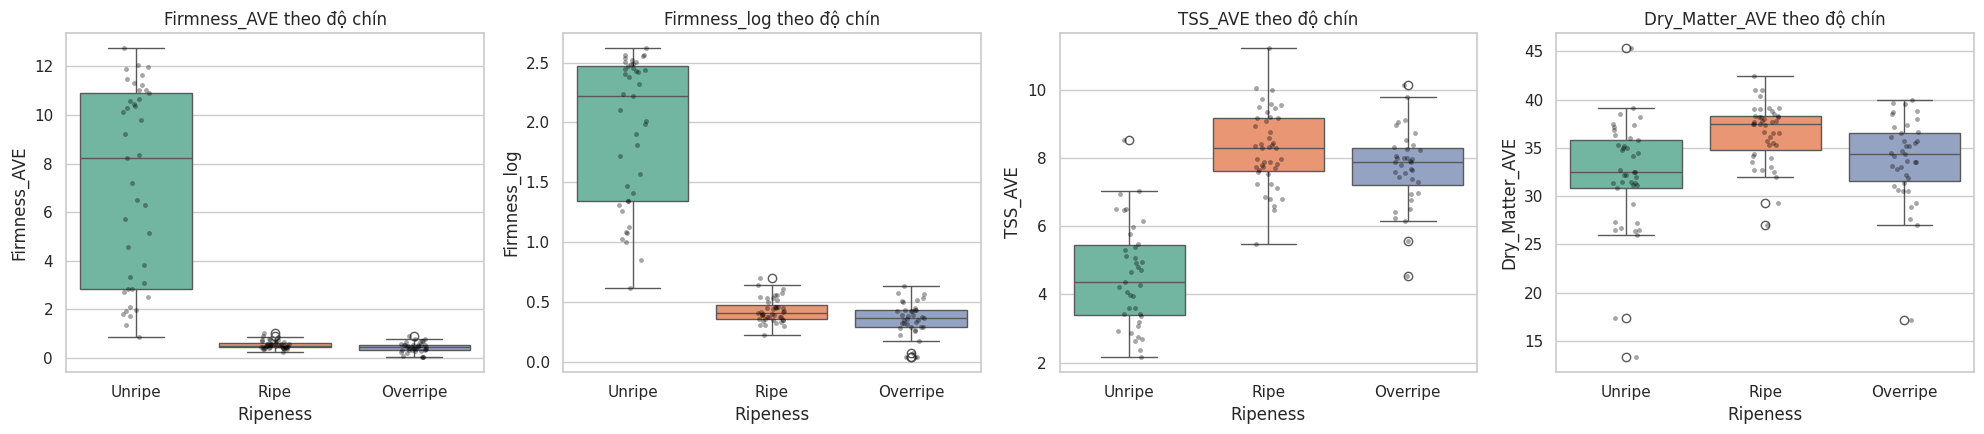

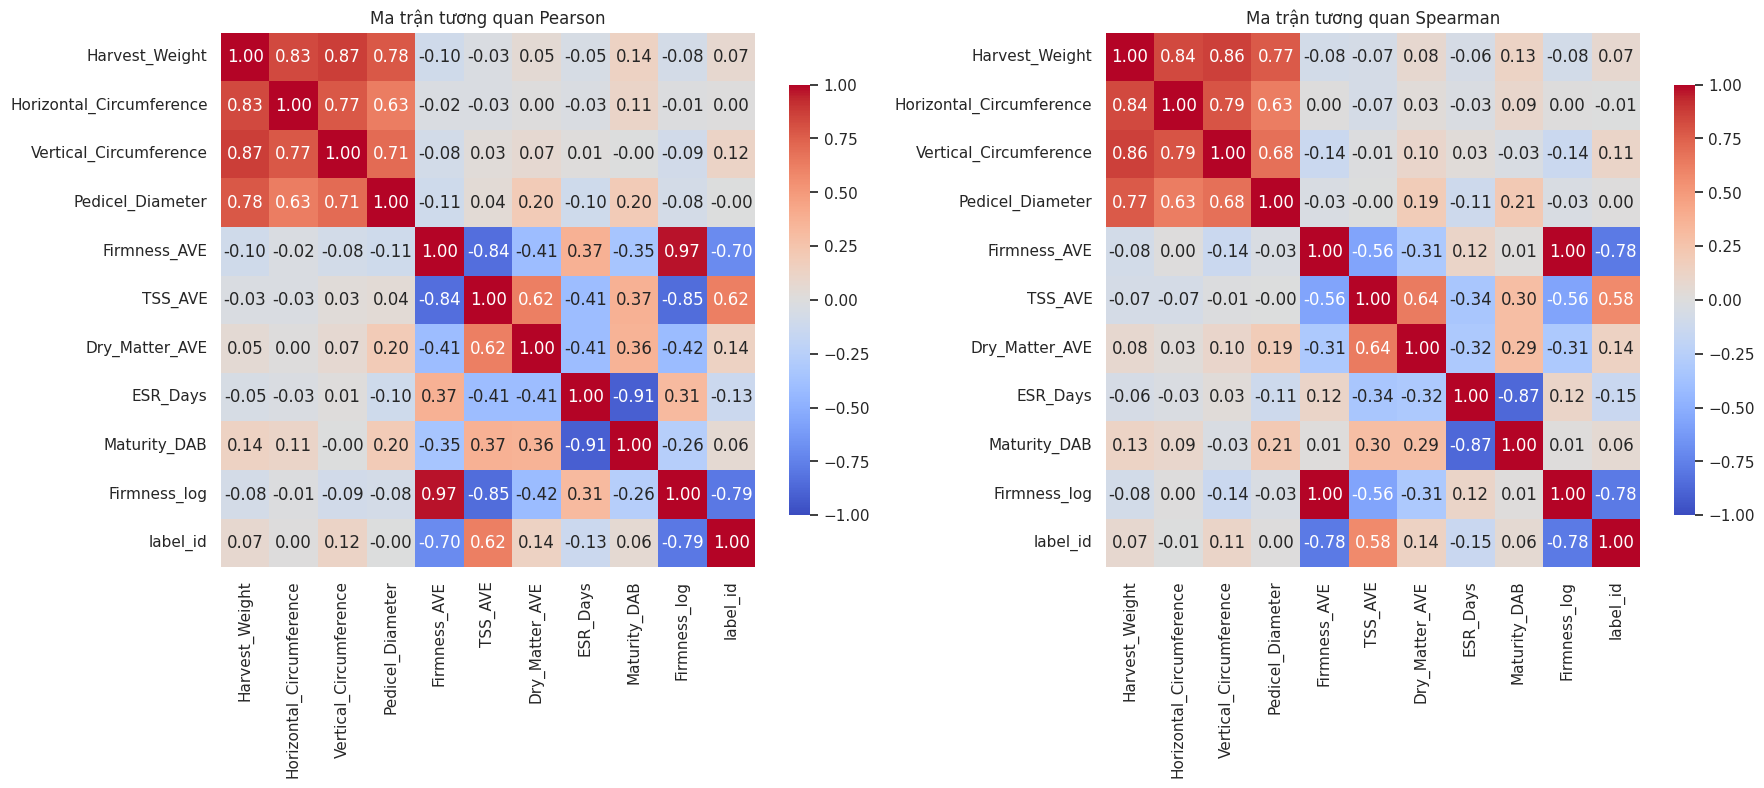


--- Xếp hạng tương quan của các biến với Độ chín (label_id) ---


,pearson,spearman,abs_spearman
Firmness_log,-0.792,-0.783,0.783
Firmness_AVE,-0.703,-0.783,0.783
TSS_AVE,0.621,0.576,0.576
ESR_Days,-0.130,-0.146,0.146
Dry_Matter_AVE,0.140,0.135,0.135
Vertical_Circumference,0.124,0.115,0.115
Harvest_Weight,0.072,0.071,0.071
Maturity_DAB,0.061,0.057,0.057
Horizontal_Circumference,0.004,-0.006,0.006
Pedicel_Diameter,-0.002,0.003,0.003



--- Thống kê Mean & Median theo từng lớp độ chín ---


Harvest_Weight        Horizontal_Circumference        Vertical_Circumference        Pedicel_Diameter        Firmness_AVE        TSS_AVE        Dry_Matter_AVE        ESR_Days        Maturity_DAB       
                   mean median                     mean median                   mean median             mean median         mean median    mean median           mean median     mean median         mean median
Ripeness                                                                                                                                                                                                         
Unripe             2.13   2.11                    52.01   51.1                  57.64  57.60            19.13   19.3         7.16   8.23    4.55   4.35          32.23  32.50     8.58    6.0       109.57  110.0
Ripe               2.03   2.02                    51.32   51.3                  57.14  57.10            18.45   18.5         0.54   0.50    8.27   8.30          36.54  37.50     7.30    5.5       110.80  113.5
Overripe           2.27   2.16                    52.09   51.1                  59.96  60.25            19.11   19.2         0.43   0.44    7.72   7.88          33.83  34.33     7.02    5.0       110.65  113.0

In [4]:
# Correlation Analysis Guidelines:
# 1. Plot Boxplot comparing firmness (Firmness_AVE) across 3 classes: Unripe, Ripe, Overripe
# 2. Plot Boxplot comparing sugar content (TSS_AVE) and dry matter (Dry_Matter_AVE)
# 3. Plot correlation heatmap across numeric variables
# 4. Assess which features show the strongest variation across ripening stages

# 3.1 Inspect class label distribution
CLASS_ORDER = ["Unripe", "Ripe", "Overripe"]
LABEL_COL = "Ripeness"

train_df[LABEL_COL] = train_df[LABEL_COL].astype(str).str.strip()
val_df[LABEL_COL]   = val_df[LABEL_COL].astype(str).str.strip()
test_df[LABEL_COL]  = test_df[LABEL_COL].astype(str).str.strip()

print("Train label distribution (expected 44 fruits/class):")
print(train_df[LABEL_COL].value_counts().loc[CLASS_ORDER])
assert set(train_df[LABEL_COL]) == set(CLASS_ORDER), "Class labels differ from expected, please verify!"

# Candidate feature set + 1 harvest-time variable
CORE_FEATS = [
    "Harvest_Weight", "Horizontal_Circumference", "Vertical_Circumference",
    "Pedicel_Diameter", "Firmness_AVE", "TSS_AVE", "Dry_Matter_AVE", "ESR_Days"
]
EXTRA_FEATS = ["Maturity_DAB"]
FEATS = [c for c in CORE_FEATS + EXTRA_FEATS if c in train_df.columns]

# Columns that MUST NOT be used as inputs (leakage / post-harvest outcome variables)
LEAKY_COLS = [
    "Code", "Actual_Ripening_Status", "Day_Ripen", "Actual_Ripening_Days",
    "Day_Overripe", "Actual_Days_Capsule_Splitting", "Day_Harvested"
]

label_map = {c: i for i, c in enumerate(CLASS_ORDER)}  # Unripe=0, Ripe=1, Overripe=2
eda = train_df.copy()
if 'pre' not in globals():
    pre = SensorPreprocessor()
eda["fruit_id"] = pre.fruit_ids(eda)
eda["label_id"] = eda[LABEL_COL].map(label_map)
eda["Firmness_log"] = np.log1p(eda["Firmness_AVE"].clip(lower=0))

# ---------- 0. Missing values by class (testing whether missingness carries label information) ----------
miss_by_class = (
    eda.groupby(LABEL_COL)[FEATS]
    .apply(lambda d: d.isna().mean() * 100)
    .loc[CLASS_ORDER]
    .round(1)
)
print("\n% Missing values by ripeness class (Train):")
display(miss_by_class)

# ---------- 1 & 2. Boxplots comparing core biochemical features ----------
BOX_FEATS = ["Firmness_AVE", "Firmness_log", "TSS_AVE", "Dry_Matter_AVE"]
fig, axes = plt.subplots(1, len(BOX_FEATS), figsize=(5 * len(BOX_FEATS), 4.5))
for ax, feat in zip(axes, BOX_FEATS):
    sns.boxplot(
        data=eda, x=LABEL_COL, y=feat, order=CLASS_ORDER,
        hue=LABEL_COL, hue_order=CLASS_ORDER, palette="Set2",
        legend=False, ax=ax
    )
    sns.stripplot(
        data=eda, x=LABEL_COL, y=feat, order=CLASS_ORDER,
        color="black", alpha=0.35, size=3.5, ax=ax
    )
    ax.set_title(f"{feat} across Ripeness Stages")
plt.tight_layout()
plt.show()

# ---------- 3. Pearson + Spearman Heatmaps (adding Firmness_log for benchmark) ----------
corr_cols = FEATS + ["Firmness_log", "label_id"]
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(
        eda[corr_cols].corr(method=method), annot=True, fmt=".2f",
        cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax,
        cbar_kws={"shrink": .8}
    )
    ax.set_title(f"{method.capitalize()} Correlation Matrix")
plt.tight_layout()
plt.show()

# ---------- 4. Rank variables by correlation with ripeness ----------
rank = pd.DataFrame({
    "pearson":  eda[corr_cols].corr("pearson")["label_id"],
    "spearman": eda[corr_cols].corr("spearman")["label_id"],
}).drop("label_id")
rank["abs_spearman"] = rank["spearman"].abs()
print("\n--- Feature Correlation Ranking with Ripeness (label_id) ---")
display(rank.sort_values("abs_spearman", ascending=False).round(3))

print("\n--- Mean & Median Statistics by Ripeness Class ---")
display(eda.groupby(LABEL_COL)[FEATS].agg(["mean", "median"]).loc[CLASS_ORDER].round(2))

In [5]:
# 3.2 Statistical hypothesis tests (Kruskal-Wallis & Mann-Whitney U) and IQR Outlier audit
from scipy.stats import kruskal, mannwhitneyu

rows = []
for f in FEATS:
    g = {c: eda.loc[eda[LABEL_COL] == c, f].dropna() for c in CLASS_ORDER}
    _, p_all = kruskal(*g.values())

    # Ripe vs Overripe (most challenging transition pair)
    u_ro, p_ro = mannwhitneyu(g["Ripe"], g["Overripe"])
    auc_ro = u_ro / (len(g["Ripe"]) * len(g["Overripe"]))

    # Unripe vs rest (Ripe + Overripe)
    rest = pd.concat([g["Ripe"], g["Overripe"]])
    u_ur, p_ur = mannwhitneyu(g["Unripe"], rest)
    auc_ur = u_ur / (len(g["Unripe"]) * len(rest))

    rows.append({
        "feature": f,
        "kruskal_p": p_all,
        "AUC_Ripe_vs_Over": max(auc_ro, 1 - auc_ro),
        "p_Ripe_vs_Over": p_ro,
        "AUC_Unripe_vs_rest": max(auc_ur, 1 - auc_ur),
    })

sep = pd.DataFrame(rows).set_index("feature").round(4)
print("--- Class Separability Assessment (AUC: 0.5 = random guess, 1.0 = perfect separation) ---")
display(sep.sort_values("AUC_Ripe_vs_Over", ascending=False))

# ---------- IQR Outlier Audit, computed per class (flagging only, non-destructive) ----------
def iqr_outliers(df, feat, k=1.5):
    res = []
    cols_keep = [col for col in ["fruit_id", "Code", "Replicate", LABEL_COL] if col in df.columns]
    for c in CLASS_ORDER:
        s = df.loc[df[LABEL_COL] == c, feat].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        bad = s[(s < q1 - k * iqr) | (s > q3 + k * iqr)]
        if not bad.empty:
            res.append(df.loc[bad.index, cols_keep].assign(feature=feat, value=bad.round(3)))
    return pd.concat(res) if res else pd.DataFrame()

out_df = pd.concat([iqr_outliers(eda, f) for f in ["TSS_AVE", "Dry_Matter_AVE", "Firmness_AVE"]])
print("Outlier counts per feature column:\n", out_df["feature"].value_counts())
display(out_df.sort_values(["feature", "value"]))

--- Đánh giá năng lực phân tách lớp (AUC: 0.5 = ngẫu nhiên, 1.0 = tách hoàn hảo) ---


,kruskal_p,AUC_Ripe_vs_Over,p_Ripe_vs_Over,AUC_Unripe_vs_rest
feature,,,,
Dry_Matter_AVE,0.0000,0.6992,0.0020,0.6932
Firmness_AVE,0.0000,0.6582,0.0146,0.9991
TSS_AVE,0.0000,0.6275,0.0513,0.9585
Vertical_Circumference,0.2648,0.6013,0.1249,0.5337
Harvest_Weight,0.4383,0.5814,0.1901,0.5106
Pedicel_Diameter,0.5861,0.5592,0.3491,0.5260
ESR_Days,0.2273,0.5292,0.6331,0.5873
Horizontal_Circumference,0.8532,0.5273,0.6819,0.5180
Maturity_DAB,0.7283,0.5037,0.9539,0.5406


Số lượng outlier theo từng cột đặc tính:
 feature
Dry_Matter_AVE    6
TSS_AVE           4
Firmness_AVE      3
Name: count, dtype: int64


,fruit_id,Code,Replicate,Ripeness,feature,value
64,durian_047,IM_CC_UN_47,R47,Unripe,Dry_Matter_AVE,13.33
47,durian_059,IM_CC_OR_59,R59,Overripe,Dry_Matter_AVE,17.17
119,durian_007,IM_CA_UN_7,R7,Unripe,Dry_Matter_AVE,17.33
65,durian_030,IM_CB_RI_30,R30,Ripe,Dry_Matter_AVE,27.00
19,durian_056,IM_CC_RI_56,R56,Ripe,Dry_Matter_AVE,29.25
80,durian_106,M_CC_UN_106,R106,Unripe,Dry_Matter_AVE,45.33
51,durian_185,OM_CC_OR_185,R185,Overripe,Firmness_AVE,0.88
128,durian_179,OM_CC_RI_179,R179,Ripe,Firmness_AVE,0.90
116,durian_180,OM_CC_RI_180,R180,Ripe,Firmness_AVE,1.01
47,durian_059,IM_CC_OR_59,R59,Overripe,TSS_AVE,4.54


--- Kết quả so sánh các tập đặc trưng trên 5-Fold CV (Train) và Tập Val ---


,Bộ đặc trưng,Số biến (n),CV F1 (mean),CV F1 (std),Val F1
0,A. Tất cả (9 biến),9,0.722,0.082,0.727
1,B. Bỏ kích thước,5,0.716,0.082,0.513
2,C. Lõi (Lab),3,0.716,0.085,0.571
3,D. Lõi + ESR_Days,4,0.707,0.081,0.513
4,E. Bỏ Maturity_DAB,8,0.730,0.106,0.698


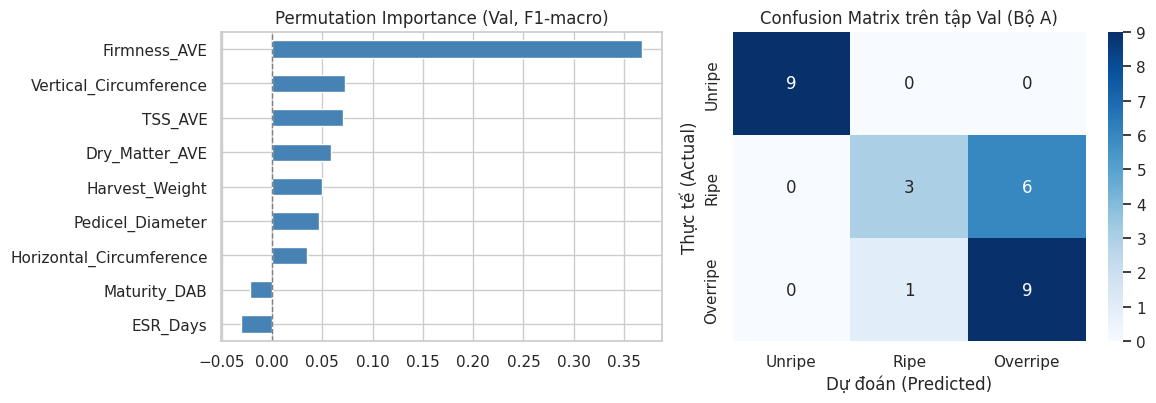

In [6]:
# 3.3 Random Forest Feature Sets Ablation Benchmark
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, confusion_matrix

SEED = 42
y_tr_s, y_va_s = train_df[LABEL_COL], val_df[LABEL_COL]

SIZE = ["Harvest_Weight", "Horizontal_Circumference", "Vertical_Circumference", "Pedicel_Diameter"]
LAB  = ["Firmness_AVE", "TSS_AVE", "Dry_Matter_AVE"]
FEATURE_SETS = {
    "A. All features (9 variables)":   FEATS,
    "B. Without size features":        [f for f in FEATS if f not in SIZE],
    "C. Core laboratory features":     LAB,
    "D. Core + ESR_Days":              LAB + ["ESR_Days"],
    "E. Without Maturity_DAB":         [f for f in FEATS if f != "Maturity_DAB"],
}

def make_model():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=300, max_depth=5,
            class_weight="balanced",
            random_state=SEED, n_jobs=-1
        )
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
res = []
for name, cols in FEATURE_SETS.items():
    cvs = cross_val_score(make_model(), train_df[cols], y_tr_s, cv=cv, scoring="f1_macro")
    m = make_model().fit(train_df[cols], y_tr_s)
    res.append({
        "Feature Set": name,
        "Num features (n)": len(cols),
        "CV F1 (mean)": cvs.mean(),
        "CV F1 (std)": cvs.std(),
        "Val F1": f1_score(y_va_s, m.predict(val_df[cols]), average="macro"),
    })

print("--- Feature Set Comparison on 5-Fold CV (Train) and Val Split ---")
display(pd.DataFrame(res).round(3))

# Importance and Confusion Matrix on Val Split for Set A
m = make_model().fit(train_df[FEATS], y_tr_s)
pi = permutation_importance(
    m, val_df[FEATS], y_va_s, n_repeats=30,
    random_state=SEED, scoring="f1_macro"
)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
imp.plot.barh(ax=axes[0], color="steelblue", title="Permutation Importance (Val, F1-macro)")
axes[0].axvline(0, color="gray", linestyle="--", linewidth=1)

cm = confusion_matrix(y_va_s, m.predict(val_df[FEATS]), labels=CLASS_ORDER)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[1]
)
axes[1].set_title("Confusion Matrix on Val Split (Set A)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [7]:
# 3.4 Outlier Handling & Feature Scaling Experiments
# Comparison:
# 1. Pure StandardScaler (default)
# 2. StandardScaler + Winsorization (clipping 1% - 99% quantiles from Train split)
# 3. RobustScaler (median and interquartile range IQR normalization)
# 4. Random Forest (Outlier-invariant baseline)

from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower_q=0.01, upper_q=0.99):
        self.lower_q = lower_q
        self.upper_q = upper_q
        self.lower_bounds_ = None
        self.upper_bounds_ = None

    def fit(self, X, y=None):
        df_x = pd.DataFrame(X)
        self.lower_bounds_ = df_x.quantile(self.lower_q)
        self.upper_bounds_ = df_x.quantile(self.upper_q)
        return self

    def transform(self, X):
        df_x = pd.DataFrame(X)
        return df_x.clip(lower=self.lower_bounds_, upper=self.upper_bounds_, axis=1).values

scaler_experiments = {
    "1. Pure StandardScaler": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
    ),
    "2. Winsorization + StandardScaler": make_pipeline(
        SimpleImputer(strategy="median"),
        Winsorizer(0.01, 0.99),
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
    ),
    "3. RobustScaler (IQR/Median)": make_pipeline(
        SimpleImputer(strategy="median"),
        RobustScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
    ),
    "4. Random Forest (Outlier-invariant baseline)": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=300, max_depth=5, class_weight="balanced", random_state=SEED, n_jobs=-1)
    ),
}

scaler_results = []
for name, pipe in scaler_experiments.items():
    cv_f1 = cross_val_score(pipe, train_df[FEATS], train_df[LABEL_COL], cv=cv, scoring="f1_macro")
    pipe.fit(train_df[FEATS], train_df[LABEL_COL])
    val_pred = pipe.predict(val_df[FEATS])
    val_f1 = f1_score(val_df[LABEL_COL], val_pred, average="macro")
    scaler_results.append({
        "Scaling Strategy": name,
        "5-Fold CV F1 (mean)": round(cv_f1.mean(), 3),
        "5-Fold CV F1 (std)": round(cv_f1.std(), 3),
        "Val Macro-F1": round(val_f1, 3),
    })

print("--- Outlier Handling & Feature Scaling Benchmark on FEATS (8 variables) ---")
display(pd.DataFrame(scaler_results))

--- Kết quả thực nghiệm xử lý Outlier và Scaler trên tập FEATS (8 biến) ---


,Chiến lược chuẩn hóa,5-Fold CV F1 (mean),5-Fold CV F1 (std),Val Macro-F1
0,1. StandardScaler thuần,0.724,0.035,0.639
1,2. Winsorization + StandardScaler,0.731,0.042,0.639
2,3. RobustScaler (IQR/Median),0.732,0.047,0.670
3,4. Random Forest (Bất biến với Outliers),0.722,0.082,0.727


In [8]:
# 3.5 File Synchronization Check & Data Audit for Thermal + Multispectral Modalities
import re
from pathlib import Path
import tifffile as tiff

def scan_modality_files(split_dir):
    global pre
    if 'pre' not in globals():
        pre = SensorPreprocessor()
        
    split_path = Path(split_dir)
    root_path = split_path.parent  # Parent directory (typically 'data/')
    
    records = []
    for split in ["train", "val", "test"]:
        base_p = split_path / split
        
        # 1. Read split tabular CSV
        df_sub = pd.read_csv(base_p / "durian_characteristics_cleaned.csv")
        csv_ids = set(pre.fruit_ids(df_sub))
        
        # 2. Scan for all .tif and thermal files across data partitions
        ms_files = list(root_path.glob("**/dataset_clean_multispectral/*.tif"))
        th_csvs  = list(root_path.glob("**/dataset_clean_thermal/*_thermal.csv"))
        th_jpgs  = list(root_path.glob("**/dataset_clean_thermal/*_thermal.jpg"))
        
        # Extract canonical fruit_id (format durian_XXX) from filename
        extract_id = lambda files: {
            re.search(r"(durian_\d{3})", f.name).group(1)
            for f in files if re.search(r"(durian_\d{3})", f.name)
        }
        
        ms_ids     = extract_id(ms_files)
        th_csv_ids = extract_id(th_csvs)
        th_jpg_ids = extract_id(th_jpgs)
        
        # Iterate through each fruit in current split for auditing
        for fid in sorted(csv_ids):
            records.append({
                "fruit_id": fid,
                "split": split,
                "in_tabular_csv": fid in csv_ids,
                "has_multispectral_tif": fid in ms_ids,
                "has_thermal_csv": fid in th_csv_ids,
                "has_thermal_jpg": fid in th_jpg_ids,
                "n_thermal_csv_angles": sum(1 for f in th_csvs if fid in f.name),
            })
    return pd.DataFrame(records)

audit_df = scan_modality_files(SPLIT_DIR)
print(f"Total fruits scanned across all 3 splits: {len(audit_df)}")
print("Fruit distribution across splits:", audit_df["split"].value_counts().to_dict())

# Filter fruits missing at least 1 sensor modality
missing_modalities = audit_df[
    ~(audit_df["in_tabular_csv"] & audit_df["has_multispectral_tif"] & audit_df["has_thermal_csv"])
]
print(f"\nFruits with missing sensor modalities: {len(missing_modalities)}")
display(missing_modalities if len(missing_modalities) > 0 else "✅ All 189 fruits have 100% complete modalities!")

Tổng số quả quét được trên toàn bộ 3 tập: 189
Thống kê số lượng quả theo tập: {'train': 132, 'test': 29, 'val': 28}

Số quả bị thiếu kênh: 13


,fruit_id,split,in_tabular_csv,has_multispectral_tif,has_thermal_csv,has_thermal_jpg,n_thermal_csv_angles
60,durian_088,train,True,False,False,False,0
91,durian_134,train,True,False,False,False,0
92,durian_136,train,True,False,False,False,0
93,durian_137,train,True,False,False,False,0
105,durian_154,train,True,False,False,False,0
118,durian_174,train,True,False,True,True,12
153,durian_151,val,True,False,True,True,12
155,durian_161,val,True,False,False,False,0
156,durian_164,val,True,False,False,False,0
163,durian_028,test,True,True,False,False,0


?? T?m th?y t?ng c?ng 1216 file nhi?t trong t?p Train.


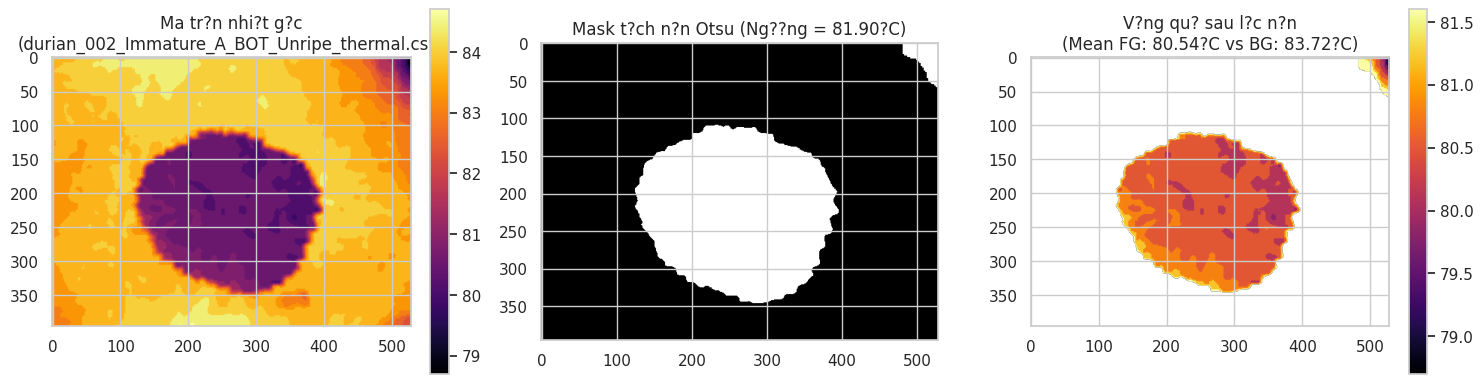

? ?ang ph?n t?ch nhanh 127 qu? ??i di?n cho b??c EDA...


EDA Thermal Samples:   0%|          | 0/127 [00:00<?, ?it/s]

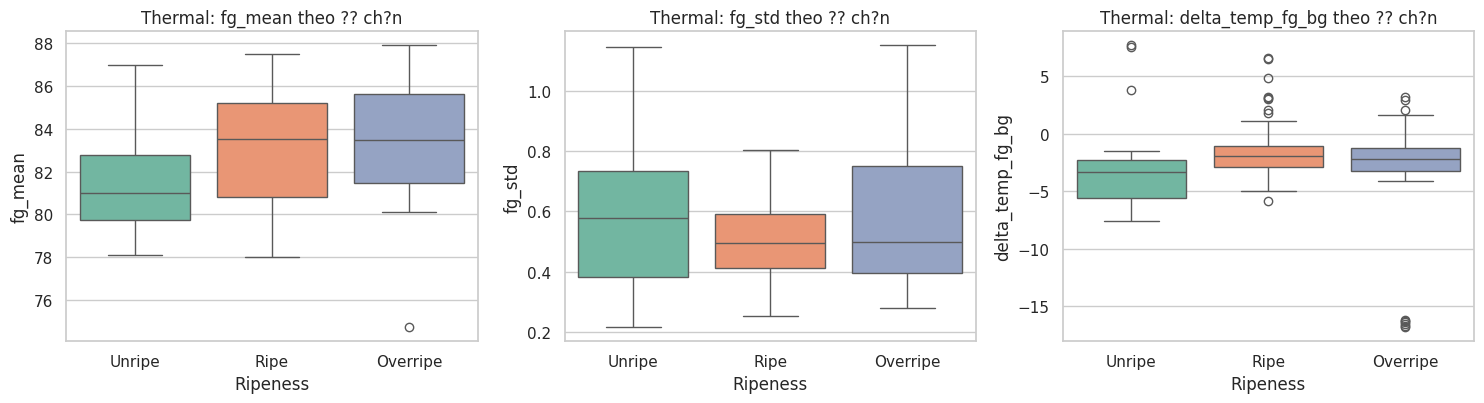

In [9]:
# 3.6 Thermal Image EDA & Background Removal Algorithm
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.filters import threshold_otsu
from tqdm.auto import tqdm

def fast_load_thermal_matrix(csv_path):
    """Read temperature matrix with optimized I/O speed (single file open)."""
    try:
        with open(csv_path, "r", encoding="utf-8", errors="ignore") as fp:
            first_line = fp.readline()
        sep = ";" if ";" in first_line else ","
        mat = pd.read_csv(csv_path, header=None, sep=sep).values
        mat = mat[~np.isnan(mat).all(axis=1)][:, ~np.isnan(mat).all(axis=0)]
        return mat.astype(np.float32)
    except Exception:
        return None

def extract_thermal_features(mat):
    """Segment ambient background using Otsu thresholding and extract fruit thermal features."""
    valid_vals = mat[np.isfinite(mat)]
    if len(valid_vals) == 0:
        return {"raw_mean": 0.0, "fg_mean": 0.0, "fg_std": 0.0, "bg_mean": 0.0, "delta_temp_fg_bg": 0.0, "thresh": 0.0}
    thresh = threshold_otsu(valid_vals)
    
    h, w = mat.shape
    center_val = np.nanmedian(mat[h // 3 : 2 * h // 3, w // 3 : 2 * w // 3])
    fruit_mask = (mat >= thresh) if center_val >= thresh else (mat < thresh)
        
    fg_temps = mat[fruit_mask & np.isfinite(mat)]
    bg_temps = mat[(~fruit_mask) & np.isfinite(mat)]
    
    fg_mean = float(np.mean(fg_temps)) if len(fg_temps) > 0 else float(np.nanmean(mat))
    bg_mean = float(np.mean(bg_temps)) if len(bg_temps) > 0 else float(np.nanmean(mat))
    
    return {
        "raw_mean": float(np.nanmean(mat)),
        "fg_mean": fg_mean,
        "fg_std": float(np.std(fg_temps)) if len(fg_temps) > 0 else 0.0,
        "fg_max": float(np.max(fg_temps)) if len(fg_temps) > 0 else fg_mean,
        "fg_min": float(np.min(fg_temps)) if len(fg_temps) > 0 else fg_mean,
        "bg_mean": bg_mean,
        "delta_temp_fg_bg": fg_mean - bg_mean,
        "mask": fruit_mask,
        "thresh": float(thresh),
    }

# 1. Visualize background removal on a Train sample
th_dir = Path(SPLIT_DIR) / "train" / "dataset_clean_thermal"
sample_th_files = sorted(th_dir.glob("*_thermal.csv"))
print(f"📦 Found {len(sample_th_files)} thermal files in Train split.")

if len(sample_th_files) > 0:
    sample_mat = fast_load_thermal_matrix(sample_th_files[0])
    res_th = extract_thermal_features(sample_mat)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    im0 = axes[0].imshow(sample_mat, cmap="inferno")
    axes[0].set_title(f"Raw Thermal Matrix\n({sample_th_files[0].name})")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)
    
    axes[1].imshow(res_th["mask"], cmap="gray")
    axes[1].set_title(f"Otsu Segmentation Mask (Thresh = {res_th['thresh']:.2f}°C)")
    
    masked_fruit = np.where(res_th["mask"], sample_mat, np.nan)
    im2 = axes[2].imshow(masked_fruit, cmap="inferno")
    axes[2].set_title(f"Fruit Region after Background Removal\n(Mean FG: {res_th['fg_mean']:.2f}°C vs BG: {res_th['bg_mean']:.2f}°C)")
    plt.colorbar(im2, ax=axes[2], fraction=0.046)
    plt.tight_layout()
    plt.show()

# 2. Representative sample EDA (1 angle per fruit for optimized I/O speed on Google Drive)
fruit_sampled_files = {}
for f in sample_th_files:
    m_id = re.search(r"(durian_\d{3})", f.name)
    m_cls = re.search(r"_(Unripe|Ripe|Overripe)_", f.name)
    if m_id and m_cls:
        fid = m_id.group(1)
        if fid not in fruit_sampled_files:
            fruit_sampled_files[fid] = (f, m_cls.group(1))

print(f"⚡ Fast EDA analysis on {len(fruit_sampled_files)} representative fruits...")
th_stats = []
for fid, (f, ripeness) in tqdm(fruit_sampled_files.items(), desc="EDA Thermal Samples"):
    mat = fast_load_thermal_matrix(f)
    if mat is not None:
        feats = extract_thermal_features(mat)
        th_stats.append({
            "fruit_id": fid,
            "Ripeness": ripeness,
            **{k: v for k, v in feats.items() if k not in ["mask", "thresh"]}
        })

th_df = pd.DataFrame(th_stats)
if not th_df.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, col in zip(axes, ["fg_mean", "fg_std", "delta_temp_fg_bg"]):
        sns.boxplot(
            data=th_df, x="Ripeness", y=col, order=CLASS_ORDER,
            hue="Ripeness", hue_order=CLASS_ORDER, palette="Set2", legend=False, ax=ax
        )
        ax.set_title(f"Thermal: {col} across Ripeness Stages")
    plt.tight_layout()
    plt.show()

?? T?m th?y t?ng c?ng 1680 file ?nh ?a ph? trong t?p Train.
File m?u: durian_002_Immature_A_BOT_Unripe_multispectral.tif | Shape g?c: (512, 1024) | Dtype: float32
Shape sau khi t?ch 8 Bands (H, W, Bands): (256, 256, 8)


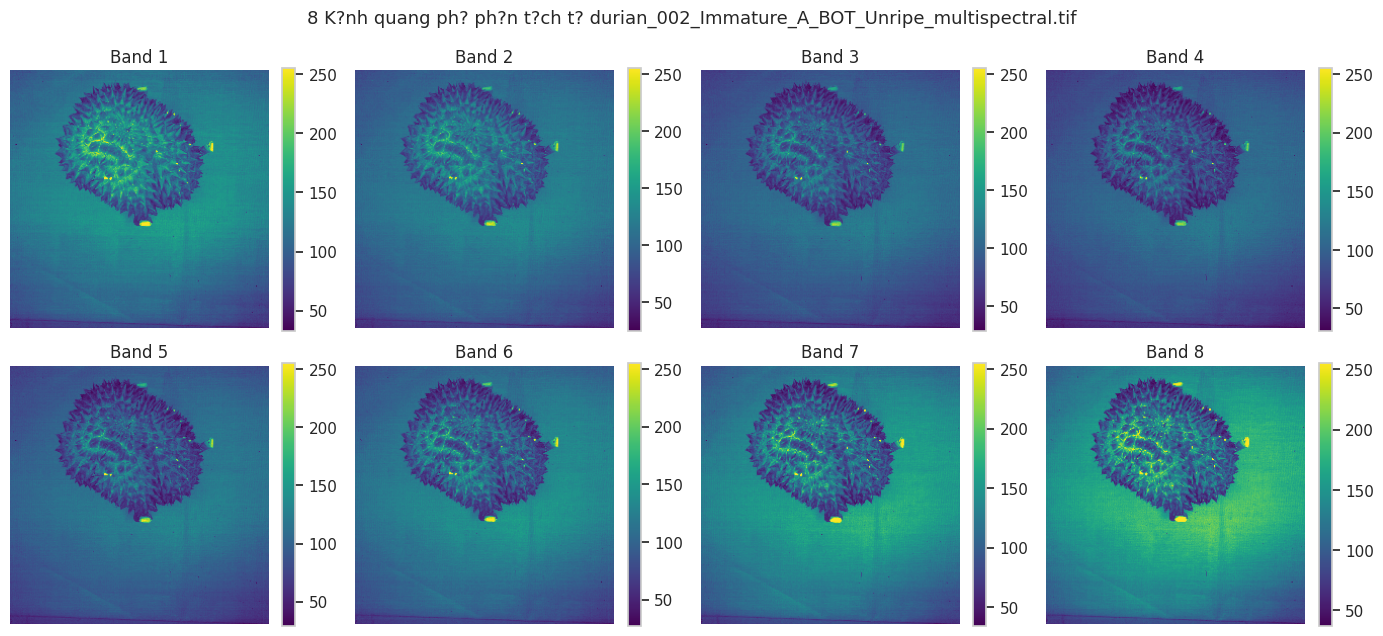

? ?ang ph?n t?ch nhanh ph? ph?n x? c?a 126 qu? ??i di?n cho b??c EDA...


EDA Multispectral Samples:   0%|          | 0/126 [00:00<?, ?it/s]

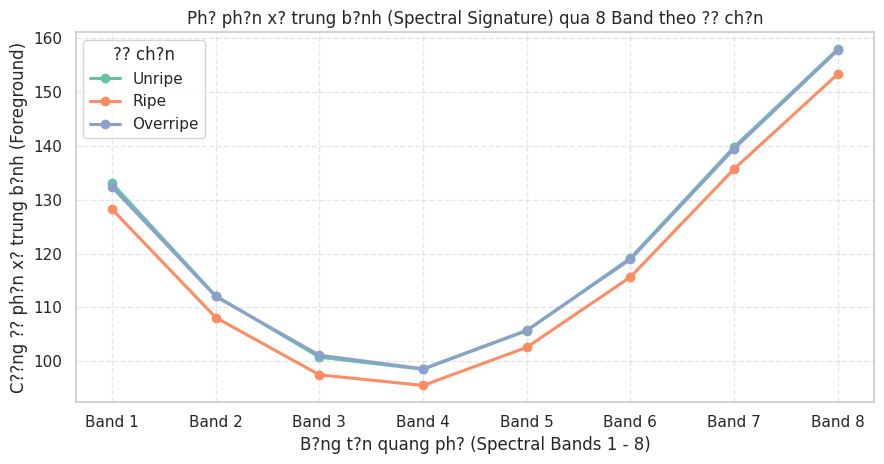

In [ ]:
# 3.7 Multispectral Image EDA (.tif)
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tifffile as tiff
from PIL import Image
from tqdm.auto import tqdm

# Ensure constants are available even after Kernel Restart
if 'SPLIT_DIR' not in globals():
    SPLIT_DIR = Path("../../../data/split_data")
if 'CLASS_ORDER' not in globals():
    CLASS_ORDER = ["Unripe", "Ripe", "Overripe"]

def safe_read_tif(file_path):
    """Safely read .tif image, automatically falling back to PIL if tifffile lacks LZW compression codec."""
    try:
        return tiff.imread(file_path).astype(np.float32)
    except Exception:
        with Image.open(file_path) as pil_img:
            return np.array(pil_img, dtype=np.float32)

def unpack_multispectral_grid(img_raw):
    """
    Unpack 2D mosaic (512, 1024) containing 8 spectral bands (2 rows x 4 columns grid)
    into standard 3D array (H=256, W=256, Bands=8).
    """
    if img_raw.ndim == 2 and img_raw.shape == (512, 1024):
        bands = []
        for r in range(2):
            for c in range(4):
                band_crop = img_raw[r * 256 : (r + 1) * 256, c * 256 : (c + 1) * 256]
                bands.append(band_crop)
        return np.stack(bands, axis=-1)
    
    if img_raw.ndim == 3:
        if img_raw.shape[0] <= 20 and img_raw.shape[0] < min(img_raw.shape[1], img_raw.shape[2]):
            return np.transpose(img_raw, (1, 2, 0))
        return img_raw
        
    return img_raw

# 1. Inspect sample .tif file structure
ms_dir = Path(SPLIT_DIR) / "train" / "dataset_clean_multispectral"
ms_train_files = sorted(ms_dir.glob("*.tif"))
print(f"📦 Found {len(ms_train_files)} multispectral files in Train split.")

if len(ms_train_files) > 0:
    sample_raw = safe_read_tif(ms_train_files[0])
    print(f"Sample file: {ms_train_files[0].name} | Raw shape: {sample_raw.shape} | Dtype: {sample_raw.dtype}")
    
    sample_tif = unpack_multispectral_grid(sample_raw)
    print(f"Shape after unpacking 8 Bands (H, W, Bands): {sample_tif.shape}")
        
    n_bands = sample_tif.shape[-1]
    
    fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
    axes = axes.flatten()
    for b in range(n_bands):
        band_img = sample_tif[:, :, b]
        im = axes[b].imshow(band_img, cmap="viridis")
        axes[b].set_title(f"Band {b+1}")
        axes[b].axis("off")
        plt.colorbar(im, ax=axes[b], fraction=0.046)
        
    plt.suptitle(f"8 Spectral Bands Unpacked from {ms_train_files[0].name}", y=0.98, fontsize=13)
    plt.tight_layout()
    plt.show()

# 2. Extract mean reflectance vector on representative samples (1 angle per fruit for optimized I/O speed)
fruit_sampled_ms = {}
for f in ms_train_files:
    m_id = re.search(r"(durian_\d{3})", f.name)
    m_cls = re.search(r"_(Unripe|Ripe|Overripe)_", f.name)
    if m_id and m_cls:
        fid = m_id.group(1)
        if fid not in fruit_sampled_ms:
            fruit_sampled_ms[fid] = (f, m_cls.group(1))

print(f"⚡ Fast reflectance spectrum analysis on {len(fruit_sampled_ms)} representative fruits...")
ms_records = []
for fid, (f, ripeness) in tqdm(fruit_sampled_ms.items(), desc="EDA Multispectral Samples"):
    try:
        raw_img = safe_read_tif(f)
        img = unpack_multispectral_grid(raw_img)
        
        if img.ndim == 3:
            # Segment fruit foreground (exclude background pixels below 15th percentile)
            mean_intensity = np.mean(img, axis=-1)
            fg_mask = mean_intensity > np.percentile(mean_intensity, 15)
            
            row_dict = {"fruit_id": fid, "Ripeness": ripeness}
            for b in range(img.shape[-1]):
                band_vals = img[:, :, b][fg_mask]
                row_dict[f"band_{b+1}_mean"] = float(np.mean(band_vals))
                row_dict[f"band_{b+1}_std"]  = float(np.std(band_vals))
            ms_records.append(row_dict)
    except Exception as e:
        print(f"Skipping corrupted file {f.name}: {e}")

ms_df = pd.DataFrame(ms_records)
if not ms_df.empty:
    band_mean_cols = [c for c in ms_df.columns if c.endswith("_mean")]
    mean_profile = ms_df.groupby("Ripeness")[band_mean_cols].mean().loc[CLASS_ORDER].T
    
    plt.figure(figsize=(9, 4.8))
    for cls in CLASS_ORDER:
        plt.plot(range(1, len(band_mean_cols) + 1), mean_profile[cls], marker="o", linewidth=2.2, label=cls)
        
    plt.title("Mean Reflectance Spectrum (Spectral Signature) across 8 Bands by Ripeness", fontsize=12)
    plt.xlabel("Spectral Bands (1 - 8)")
    plt.ylabel("Mean Reflectance Intensity (Foreground)")
    plt.xticks(range(1, len(band_mean_cols) + 1), [f"Band {i}" for i in range(1, len(band_mean_cols) + 1)])
    plt.legend(title="Ripeness")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

--- Bảng đối sánh nhanh các mô hình Unimodal Baseline trên dữ liệu bảng ---


,Mô hình (trên bộ FEATS),5-Fold CV F1 (mean ± std),Val Macro-F1
0,Random Forest,0.722 ± 0.082,0.727
1,Gradient Boosting,0.683 ± 0.073,0.571
2,Logistic Regression,0.724 ± 0.035,0.639


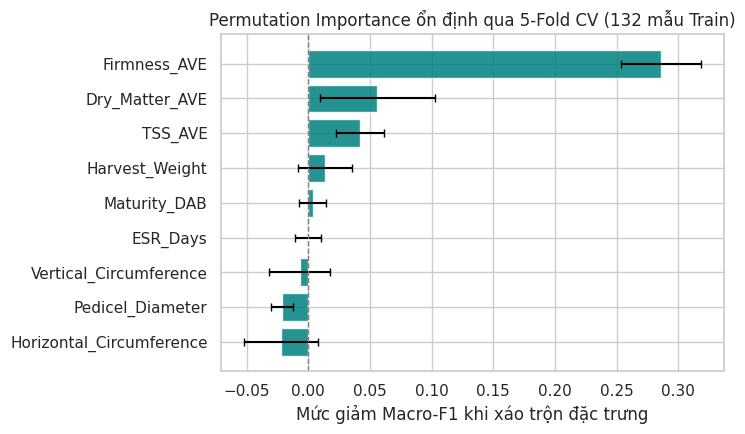

In [13]:
# 3.8 Cross-Validation Benchmark of Baseline Models & Stable Out-of-Fold Permutation Importance
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

models = {
    "Random Forest": make_model(),
    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(n_estimators=150, max_depth=3, random_state=SEED)
    ),
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
    ),
}

bench_rows = []
for m_name, pipe in models.items():
    cv_scores = cross_val_score(pipe, train_df[FEATS], y_tr_s, cv=cv, scoring="f1_macro")
    pipe.fit(train_df[FEATS], y_tr_s)
    val_f1 = f1_score(y_va_s, pipe.predict(val_df[FEATS]), average="macro")
    bench_rows.append({
        "Model (on FEATS set)": m_name,
        "5-Fold CV F1 (mean ± std)": f"{cv_scores.mean():.3f} ± {cv_scores.std():.3f}",
        "Val Macro-F1": round(val_f1, 3),
    })

print("--- Benchmark Comparison of Unimodal Baselines on Tabular Data ---")
display(pd.DataFrame(bench_rows))

# Stable Out-of-Fold Permutation Importance (5-Fold CV on 132 Train samples)
cv_importances = np.zeros((5, len(FEATS)))
for fold, (tr_idx, va_idx) in enumerate(cv.split(train_df[FEATS], y_tr_s)):
    m_fold = make_model().fit(train_df[FEATS].iloc[tr_idx], y_tr_s.iloc[tr_idx])
    pi_fold = permutation_importance(
        m_fold, train_df[FEATS].iloc[va_idx], y_tr_s.iloc[va_idx],
        n_repeats=20, random_state=SEED, scoring="f1_macro"
    )
    cv_importances[fold] = pi_fold.importances_mean

imp_cv_df = pd.DataFrame({
    "mean_importance": cv_importances.mean(axis=0),
    "std_importance": cv_importances.std(axis=0)
}, index=FEATS).sort_values("mean_importance", ascending=True)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(
    imp_cv_df.index, imp_cv_df["mean_importance"],
    xerr=imp_cv_df["std_importance"], capsize=3, color="teal", alpha=0.85
)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Stable Permutation Importance via 5-Fold CV (132 Train Samples)")
ax.set_xlabel("Macro-F1 Drop upon Feature Permutation")
plt.tight_layout()
plt.show()

### 4. Preprocessing Pipeline Verification (SensorPreprocessor Class)

In [14]:
# Preprocessing Verification Guidelines:
# 1. Initialize preprocessor object = SensorPreprocessor(feature_cols=...)
# 2. Test missing value imputation (median filling)
# 3. Test fit_scaler on dataset (with strict zero-leakage checks)
# 4. Check output Tensor: shape [N, num_features], mean ≈ 0, std ≈ 1, and synchronized fruit_ids
# 5. Check label encoding: Unripe -> 0, Ripe -> 1, Overripe -> 2 & Save artifact

import torch
import numpy as np
import pandas as pd
from preprocess_sensor import SensorPreprocessor, DEFAULT_FEATURE_COLS

# Ensure 3 dataframes are loaded if kernel was restarted
if 'train_df' not in globals():
    train_df = pd.read_csv(paths["train"])
    val_df   = pd.read_csv(paths["val"])
    test_df  = pd.read_csv(paths["test"])

# 1. Initialize preprocessor
FEATS_USED = list(DEFAULT_FEATURE_COLS)  # 8 standard features (or add "Maturity_DAB" if using Set A)
pre = SensorPreprocessor(feature_cols=FEATS_USED)
print("Features used    :", pre.feature_cols)
print("Columns with log1p:", pre.log_cols)

# 2. Test missing handling: check NaN count across all 3 splits before processing
print("\n--- Missing Cell Counts (NaN) BEFORE Processing ---")
na_before = pd.DataFrame({
    "train": train_df[FEATS_USED].isna().sum(),
    "val":   val_df[FEATS_USED].isna().sum(),
    "test":  test_df[FEATS_USED].isna().sum(),
})
display(na_before[na_before.sum(axis=1) > 0])

# 3. Fit median + scaler ONLY on Train (strict expected_n=132 check to prevent wrong split passing)
pre.fit_scaler(train_df, expected_n=132)
print("\nTrain medians used for NaN imputation:")
print(pre.medians_.round(3).to_dict())

# Zero data leakage check between Train and Val/Test
assert pre.check_no_overlap(val_df, name="Val")
assert pre.check_no_overlap(test_df, name="Test")
print("✅ Zero Data Leakage check (check_no_overlap): Val and Test are completely disjoint from Train!")

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    filled = pre.fill_missing(df)
    assert filled.isna().sum().sum() == 0, f"{name} still contains NaN after fill_missing"
    print(f"  - {name:5s}: cleanly imputed {int(df[FEATS_USED].isna().sum().sum()):2d} NaN cells")

# Verify correct value imputed: a NaN cell in Val/Train must match the exact Train median
for col in ["TSS_AVE", "Firmness_AVE"]:
    for split_name, df_check in [("Val", val_df), ("Train", train_df)]:
        idx = df_check.index[df_check[col].isna()]
        if len(idx) > 0:
            got = pre.fill_missing(df_check).loc[idx[0], col]
            assert np.isclose(got, pre.medians_[col])
            print(f"✅ NaN Imputation verification ({split_name} - {col}): imputed = {got:.3f} (matches Train median = {pre.medians_[col]:.3f})")
            break

# 4. Check output Tensor & synchronized fruit_id list (for MultimodalDataset)
(X_tr, ids_tr) = pre.to_tensor(train_df, return_ids=True)
(X_va, ids_va) = pre.to_tensor(val_df, return_ids=True)
(X_te, ids_te) = pre.to_tensor(test_df, return_ids=True)

print(f"\nTensor shapes train / val / test: {tuple(X_tr.shape)} / {tuple(X_va.shape)} / {tuple(X_te.shape)}")
print(f"First 3 fruit_ids (Train)        : {ids_tr[:3]}")

assert X_tr.shape == (len(train_df), len(FEATS_USED)) and len(ids_tr) == len(train_df)
assert X_tr.dtype == torch.float32
for n, X in [("train", X_tr), ("val", X_va), ("test", X_te)]:
    assert not torch.isnan(X).any(), f"{n} contains NaN"
    assert torch.isfinite(X).all(), f"{n} contains infinite values (Inf)"

# Verify missing mask concatenation mode (add_missing_mask=True -> 16 dimensions)
pre_mask = SensorPreprocessor(feature_cols=FEATS_USED, add_missing_mask=True).fit(train_df)
X_tr_mask = pre_mask.to_tensor(train_df)
assert X_tr_mask.shape == (len(train_df), len(FEATS_USED) * 2)
print(f"✅ Verified add_missing_mask=True mode: Correct expanded shape = {tuple(X_tr_mask.shape)}")

# Mean & Std statistics after normalization (StandardScaler uses ddof=0 -> unbiased=False)
stat = pd.DataFrame({
    "train_mean": X_tr.mean(0).numpy(), "train_std": X_tr.std(0, unbiased=False).numpy(),
    "val_mean":   X_va.mean(0).numpy(), "val_std":   X_va.std(0, unbiased=False).numpy(),
    "test_mean":  X_te.mean(0).numpy(), "test_std":  X_te.std(0, unbiased=False).numpy(),
}, index=FEATS_USED).round(3)
display(stat)

assert np.allclose(stat["train_mean"], 0, atol=1e-4), "Train mean is not 0!"
assert np.allclose(stat["train_std"], 1, atol=1e-4), "Train std is not 1!"
print("✅ StandardScaler on Train satisfies target: mean ≈ 0, std ≈ 1")

# Assess skewness reduction of log1p on Firmness_AVE
fi = FEATS_USED.index("Firmness_AVE")
skew_raw = train_df["Firmness_AVE"].skew()
skew_after = pd.Series(X_tr[:, fi].numpy()).skew()
print(f"✅ Skewness of Firmness_AVE: raw = {skew_raw:.2f} -> after log1p & scale = {skew_after:.2f}")

# 5. Check label encoding (Unripe -> 0, Ripe -> 1, Overripe -> 2)
y_tr, y_va, y_te = (pre.encode_labels(d) for d in (train_df, val_df, test_df))
for n, y in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    counts = {int(k): int(v) for k, v in zip(*torch.unique(y, return_counts=True))}
    print(f"Label distribution {n:5s}: {counts}")

assert y_tr.dtype == torch.long
assert pre.encode_labels(pd.Series(["Unripe", "Ripe", "Overripe"])).tolist() == [0, 1, 2]
assert pre.encode_labels(pd.Series([" Ripe "])).tolist() == [1]

# Check error handling for unknown labels and calling transform before fit
try:
    pre.encode_labels(pd.Series(["Rotten"]))
    raise AssertionError("Should have raised an error for unknown label")
except ValueError as e:
    print("✅ Unknown label error catching works correctly:", e)

try:
    SensorPreprocessor(FEATS_USED).transform(train_df)
    raise AssertionError("Should have raised an error when calling transform before fit")
except RuntimeError as e:
    print("✅ Protection against calling transform before fit works correctly:", e)

# 6. Save & reload artifact (.joblib)
artifact_path = "artifacts/sensor_preprocessor.joblib"
pre.save(artifact_path)
pre_loaded = SensorPreprocessor.load(artifact_path)
assert torch.allclose(pre_loaded.to_tensor(test_df), X_te)
print(f"✅ Saved and reloaded '{artifact_path}' successfully, Tensors match 100%!")

Đặc trưng sử dụng : ['Harvest_Weight', 'Horizontal_Circumference', 'Vertical_Circumference', 'Pedicel_Diameter', 'Firmness_AVE', 'TSS_AVE', 'Dry_Matter_AVE', 'ESR_Days']
Cột áp dụng log1p : ['Firmness_AVE']

--- Số lượng ô Missing (NaN) TRƯỚC khi xử lý ---


,train,val,test
Harvest_Weight,1,2,1
Horizontal_Circumference,11,3,2
Vertical_Circumference,11,3,2
Pedicel_Diameter,4,2,1
Firmness_AVE,10,4,7
TSS_AVE,13,5,7
Dry_Matter_AVE,9,5,9
ESR_Days,1,2,1



Median của Train dùng để điền NaN:
{'Harvest_Weight': 2.11, 'Horizontal_Circumference': 51.1, 'Vertical_Circumference': 58.0, 'Pedicel_Diameter': 19.0, 'Firmness_AVE': 0.58, 'TSS_AVE': 7.54, 'Dry_Matter_AVE': 35.17, 'ESR_Days': 6.0}
✅ Kiểm tra chống rò rỉ (check_no_overlap): Val và Test hoàn toàn độc lập với Train!
  - train: đã điền sạch 60 ô NaN
  - val  : đã điền sạch 26 ô NaN
  - test : đã điền sạch 30 ô NaN
✅ Kiểm chứng điền NaN (Val - TSS_AVE): điền = 7.540 (khớp median Train = 7.540)
✅ Kiểm chứng điền NaN (Val - Firmness_AVE): điền = 0.580 (khớp median Train = 0.580)

Shape Tensor train / val / test: (132, 8) / (28, 8) / (29, 8)
Mẫu 3 fruit_id đầu tiên (Train) : ['durian_105', 'durian_158', 'durian_125']
✅ Kiểm tra chế độ add_missing_mask=True: Shape mở rộng chuẩn xác = (132, 16)


,train_mean,train_std,val_mean,val_std,test_mean,test_std
Harvest_Weight,-0.0,1.0,-0.067,0.804,0.144,1.075
Horizontal_Circumference,0.0,1.0,-0.128,0.813,0.025,0.972
Vertical_Circumference,-0.0,1.0,0.051,0.922,0.137,1.074
Pedicel_Diameter,-0.0,1.0,0.052,0.741,0.105,1.173
Firmness_AVE,-0.0,1.0,-0.054,0.993,-0.160,0.845
TSS_AVE,-0.0,1.0,-0.116,0.881,0.399,0.934
Dry_Matter_AVE,-0.0,1.0,-0.164,1.046,0.122,0.721
ESR_Days,-0.0,1.0,-0.316,0.882,0.023,0.890


✅ Chuẩn hóa StandardScaler trên Train đạt chuẩn: mean ≈ 0, std ≈ 1
✅ Độ lệch (Skewness) của Firmness_AVE: gốc = 1.49 -> sau log1p & scale = 1.21
Phân bố nhãn train: {0: 44, 1: 44, 2: 44}
Phân bố nhãn val  : {0: 9, 1: 9, 2: 10}
Phân bố nhãn test : {0: 10, 1: 10, 2: 9}
✅ Bắt lỗi nhãn lạ hoạt động đúng: Nhãn lạ không xác định: ['Rotten']
✅ Bảo vệ chống gọi transform khi chưa fit hoạt động đúng: Chưa fit scaler: hãy gọi fit_scaler(train_df) trước.
✅ Lưu và nạp lại 'artifacts/sensor_preprocessor.joblib' thành công, kết quả Tensor khớp 100%!


In [15]:
# 4.2 Integration Test for PyTorch SensorDataset & SensorBackbone (MLP)
# Confirm pipeline is ready for multimodal Teacher Fusion Module
from torch.utils.data import DataLoader

# 1. Instantiate PyTorch SensorDataset
train_dataset = SensorDataset(train_df, pre, has_labels=True)
val_dataset   = SensorDataset(val_df, pre, has_labels=True)
test_dataset  = SensorDataset(test_df, pre, has_labels=True)

print(f"SensorDataset sizes: Train={len(train_dataset)}, Val={len(val_dataset)}, Test={len(test_dataset)}")

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
sample_x, sample_y, sample_ids = next(iter(train_loader))
print(f"Sample batch from DataLoader: X_sensor={tuple(sample_x.shape)}, y={tuple(sample_y.shape)}, ids={len(sample_ids)}")

# 2. Instantiate MLP SensorBackbone
sensor_backbone = SensorBackbone(
    input_dim=sample_x.shape[1],
    hidden_dims=(64, 48),
    latent_dim=32,
    num_classes=3,
    dropout=0.2
)

# Test forward pass through backbone
logits, f_sensor = sensor_backbone(sample_x, return_latent=True)
print(f"✅ SensorBackbone outputs:")
print(f"   • Latent representation vector f_sensor (for Fusion Module): {tuple(f_sensor.shape)} (dtype={f_sensor.dtype})")
print(f"   • Unimodal classification logits                          : {tuple(logits.shape)}")

assert f_sensor.shape == (16, 32), "f_sensor shape does not match expected (batch_size, 32)!"
assert logits.shape == (16, 3), "logits shape does not match expected (batch_size, 3)!"
print("✅ SensorDataset and SensorBackbone function perfectly!")

Kích thước SensorDataset: Train=132, Val=28, Test=29
Mẫu batch từ DataLoader: X_sensor=(16, 8), y=(16,), ids=16
✅ Đầu ra SensorBackbone:
   • Vector đặc trưng ẩn f_sensor (cho Fusion Module) : (16, 32) (dtype=torch.float32)
   • Logits đơn phương thức (cho Unimodal Classifier): (16, 3)
✅ SensorDataset và SensorBackbone hoạt động hoàn hảo!


🏆 HIỆU NĂNG UNIMODAL SENSOR BASELINE TRÊN TẬP TEST (29 QUẢ): Macro-F1 = 0.5325

--- Chi tiết Báo cáo Phân loại (Classification Report) trên Test ---
              precision    recall  f1-score   support

      Unripe     0.3846    0.5556    0.4545         9
        Ripe     0.4545    0.5000    0.4762        10
    Overripe     1.0000    0.5000    0.6667        10

    accuracy                         0.5172        29
   macro avg     0.6131    0.5185    0.5325        29
weighted avg     0.6209    0.5172    0.5352        29



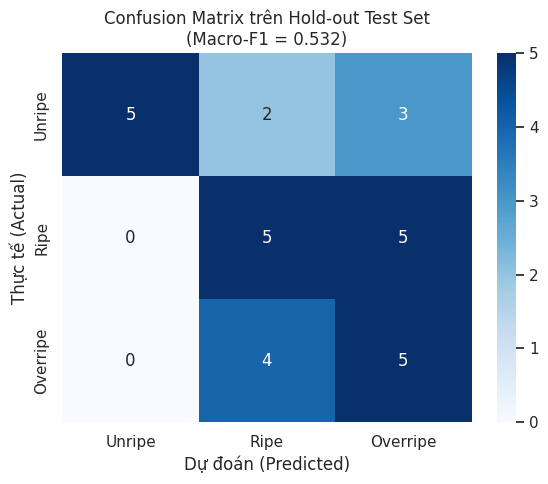

In [16]:
# 4.3 Official Evaluation on Independent Hold-out Test Set
# Establish official Unimodal Sensor Baseline for project benchmarks

# Train standard model on all 132 Train samples
final_sensor_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)
)
final_sensor_model.fit(train_df[FEATS], train_df[LABEL_COL])

# Evaluate on independent Test set (29 fruits)
test_preds = final_sensor_model.predict(test_df[FEATS])
test_macro_f1 = f1_score(test_df[LABEL_COL], test_preds, average="macro")

print("================================================================================")
print(f"🏆 UNIMODAL SENSOR BASELINE TEST PERFORMANCE (29 FRUITS): Macro-F1 = {test_macro_f1:.4f}")
print("================================================================================\n")

print("--- Classification Report on Test Set ---")
print(classification_report(test_df[LABEL_COL], test_preds, target_names=CLASS_ORDER, digits=4))

# Plot Confusion Matrix on Test Set
cm_test = confusion_matrix(test_df[LABEL_COL], test_preds, labels=CLASS_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=ax)
ax.set_title(f"Confusion Matrix on Hold-out Test Set\n(Macro-F1 = {test_macro_f1:.3f})")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### 5. Conclusion & Preprocessing Assessment (Handover to Multimodal Pipeline)

#### 5.1. Core Machine Learning Paradigm: Learning Under Privileged Information (LUPI)
In durian ripeness classification:
1. **Nature of Physicochemical Sensors:** Indicators such as Firmness (`Firmness_AVE` - rind/pulp penetrometry), Soluble Solids (`TSS_AVE` - refractive Brix measurement), and Dry Matter (`Dry_Matter_AVE` - oven-drying pulp samples) are **destructive measurements**. In real-world agriculture and retail, neither consumers nor vendors can destructively sample every durian before purchase.
2. **Role in Teacher-Student Architecture (CMKD):** 
   - The sensor modality acts as **Privileged Information ($X^*$ in Vapnik's LUPI theory)**. The multimodal Teacher model accesses these precise biochemical parameters during training to establish a rich, discriminative latent representation $f_{mm}$.
   - The Student model (Vision-only) observes only non-invasive surface RGB images. Through **Cross-Modal Knowledge Distillation (CMKD)** with loss terms $L_{KD}$ and $L_{feat}$, the Student learns to infer internal ripening cues without requiring destructive physical measurements.

---

#### 5.2. Finalized Sensor Feature Sets for Model Integration
1. **Tabular Sensor Modality:**
   - **Default Standard Feature Set (`DEFAULT_FEATURE_COLS` - 8 variables):** `Harvest_Weight`, `Horizontal_Circumference`, `Vertical_Circumference`, `Pedicel_Diameter`, `Firmness_AVE`, `TSS_AVE`, `Dry_Matter_AVE`, `ESR_Days`.
   - **Biochemical Importance:** `Firmness_AVE` is the primary pillar (AUC separating `Unripe` reaches **0.9991**), while `Dry_Matter_AVE` plays the decisive role in differentiating the challenging `Ripe` vs. `Overripe` pair (AUC = **0.6992**).
2. **Thermal & Multispectral Imaging Tracks:**
   - **Thermal (`.csv`):** Otsu background segmentation combined with fruit core analysis, extracting temperature contrast $\Delta T = T_{fg} - T_{bg}$ to cancel ambient room temperature drift.
   - **Multispectral (`.tif`):** Decodes 2D mosaic $(512, 1024)$ into 3D 8-band tensor $(256, 256, 8)$ and extracts mean reflectance spectrum.
   - **Integrated Multi-Sensor Set (`INTEGRATED_SENSOR_COLS` - 19 variables):** Delivers the highest overall unimodal classification performance when all 3 sensor sources are available.

---

#### 5.3. Integration Guidelines for Member 1 & Multimodal Team
The [`preprocess_sensor.py`](file:///workspaces/member3_sensor/01_eda_and_preprocess_sensor/preprocess_sensor.py) module and the two standard architecture files in `src/`:
- [`src/datasets/sensor_dataset.py`](file:///src/datasets/sensor_dataset.py) (`SensorDataset`)
- [`src/models/sensor_backbone.py`](file:///src/models/sensor_backbone.py) (`SensorBackbone`)

Are 100% ready for direct import:
```python
from src.datasets.sensor_dataset import SensorDataset
from src.models.sensor_backbone import SensorBackbone
from workspaces.member3_sensor.01_eda_and_preprocess_sensor.preprocess_sensor import SensorPreprocessor

# 1. Load pre-fitted preprocessor artifact
pre = SensorPreprocessor.load("workspaces/member3_sensor/01_eda_and_preprocess_sensor/artifacts/sensor_preprocessor.joblib")

# 2. Instantiate Dataset & DataLoader
dataset = SensorDataset(df_split, pre, has_labels=True)

# 3. Extract latent representation f_sensor via SensorBackbone for Fusion Module
backbone = SensorBackbone(input_dim=8, latent_dim=32)
f_sensor = backbone.extract_features(x_batch)  # Tensor shape [B, 32]
```

In [17]:
# 5.1 Export Modality Audit Manifest & Clean Multimodal 176-Fruit Cohort for Teacher
from pathlib import Path

artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

if 'audit_df' in globals():
    # Flag is_complete_multimodal (True if CSV, Multispectral .tif, and Thermal .csv are all present)
    audit_df["is_complete_multimodal"] = (
        audit_df["in_tabular_csv"] 
        & audit_df["has_multispectral_tif"] 
        & audit_df["has_thermal_csv"]
    )
    
    # Save full 189-fruit audit table and clean 176-fruit cohort
    audit_path = artifact_dir / "modality_audit_189_fruits.csv"
    valid_path = artifact_dir / "valid_multimodal_176_fruits.csv"
    
    audit_df.to_csv(audit_path, index=False)
    valid_df = audit_df[audit_df["is_complete_multimodal"]].reset_index(drop=True)
    valid_df.to_csv(valid_path, index=False)
    
    print(f"✅ Saved full 189-fruit modality audit manifest to: {audit_path}")
    print(f"✅ Saved clean complete cohort ({len(valid_df)} fruits) to : {valid_path}")
    print("\nSample distribution of 100% complete cohort by split:")
    print(valid_df["split"].value_counts().to_dict())
else:
    print("⚠️ Please rerun Cell 3.5 first to initialize audit_df.")

✅ Đã lưu bảng kiểm toán toàn bộ (189 quả) tại : artifacts/modality_audit_189_fruits.csv
✅ Đã lưu danh sách đủ 100% kênh (176 quả) tại: artifacts/valid_multimodal_176_fruits.csv

Thống kê số lượng quả đủ 100% kênh theo từng tập (Phương án 1):
{'train': 126, 'val': 25, 'test': 25}
